In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn ucimlrepo

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\Carlos\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Setup complete!")

Python: 3.13.14
Pandas: 3.0.2
Scikit-learn: 1.9.1
Setup complete!


In [3]:
from ucimlrepo import fetch_ucirepo

# Download the dataset from UCI.
heart_disease = fetch_ucirepo(id=45)

# Combine the predictors and target into one table.
df_original = pd.concat(
    [
        heart_disease.data.features,
        heart_disease.data.targets
    ],
    axis=1
)

# Create a separate working copy.
df = df_original.copy()

print("Dataset dimensions:", df.shape)
display(df.head())

Dataset dimensions: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [4]:
# Show column names, non-missing counts, and data types.
df.info()

# Count missing values in every column.
print("\nMissing values per column:")
print(df.isna().sum())

# Count patients in each original diagnosis category.
print("\nOriginal target counts:")
print(df["num"].value_counts().sort_index())

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype:

In [5]:
# Identify patients missing either ca or thal.
missing_mask = df[["ca", "thal"]].isna().any(axis=1)

# Inspect affected records before removing them.
print("Rows with missing ca or thal:", missing_mask.sum())
display(df.loc[missing_mask])

# Create a cleaned table while preserving df and df_original.
df_clean = df.dropna(subset=["ca", "thal"]).copy()

# Check the result.
print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Remaining missing values:", df_clean.isna().sum().sum())

Rows with missing ca or thal: 6


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53,0,3,128,216,0,2,115,0,0.0,1,0.0,NaN,0
166,52,1,3,138,223,0,0,169,0,0.0,1,NaN,3.0,0
192,43,1,4,132,247,1,2,143,1,0.1,2,NaN,7.0,1
266,52,1,4,128,204,1,0,156,1,1.0,2,0.0,NaN,2
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0,0
302,38,1,3,138,175,0,0,173,0,0.0,1,NaN,3.0,0


Rows before cleaning: 303
Rows after cleaning: 297
Rows removed: 6
Remaining missing values: 0


In [6]:
# Count exact duplicate rows after their first occurrence.
duplicate_count = df_clean.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

# If duplicates exist, display all copies for inspection.
if duplicate_count > 0:
    display(df_clean[df_clean.duplicated(keep=False)])

Exact duplicate rows: 0


In [7]:
# Verify that the original target contains only expected values.
assert df_clean["num"].isin([0, 1, 2, 3, 4]).all(), \
    "Unexpected or missing target values found."

# Convert the original diagnosis into a binary target.
df_clean["target"] = (df_clean["num"] > 0).astype(int)

# Inspect the conversion.
display(df_clean[["num", "target"]].head(10))

# Summarize the number and percentage of patients in each class.
target_counts = df_clean["target"].value_counts().sort_index()

target_summary = pd.DataFrame({
    "Patients": target_counts,
    "Percentage": (target_counts / len(df_clean) * 100).round(2)
})

target_summary.index.name = "Target"
display(target_summary)

,num,target
0,0,0
1,2,1
2,1,1
3,0,0
4,0,0
5,0,0
6,3,1
7,0,0
8,2,1
9,1,1


,Patients,Percentage
Target,,
0,160,53.87
1,137,46.13


In [8]:
display(target_summary)

,Patients,Percentage
Target,,
0,160,53.87
1,137,46.13


In [9]:
from sklearn.model_selection import train_test_split

# Predictors: remove both columns that reveal the diagnosis.
X = df_clean.drop(columns=["num", "target"])

# Target: the binary diagnosis we want to predict.
y = df_clean["target"]

# Reserve 20% of the patients for final testing.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target counts:")
print(y_train.value_counts().sort_index())

print("\nTesting target counts:")
print(y_test.value_counts().sort_index())

# Confirm that no row appears in both sets.
shared_rows = X_train.index.intersection(X_test.index)
print("\nRows shared between training and testing:", len(shared_rows))

Training features: (237, 13)
Testing features: (60, 13)

Training target counts:
target
0    128
1    109
Name: count, dtype: int64

Testing target counts:
target
0    32
1    28
Name: count, dtype: int64

Rows shared between training and testing: 0


In [10]:
# Define predictor groups based on their meaning.
numerical_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak", "ca"
]

binary_features = [
    "sex", "fbs", "exang"
]

categorical_features = [
    "cp", "restecg", "slope", "thal"
]

# Confirm that every predictor belongs to exactly one group.
all_features = (
    numerical_features
    + binary_features
    + categorical_features
)

assert len(all_features) == len(set(all_features)), \
    "A predictor appears in more than one group."

assert set(all_features) == set(X_train.columns), \
    "The groups do not match the predictor columns."

# Inspect the observed category codes.
print("Category values in the training data:")

for column in binary_features + categorical_features:
    values = sorted(X_train[column].unique())
    print(f"{column}: {values}")

Category values in the training data:
sex: [np.int64(0), np.int64(1)]
fbs: [np.int64(0), np.int64(1)]
exang: [np.int64(0), np.int64(1)]
cp: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
restecg: [np.int64(0), np.int64(1), np.int64(2)]
slope: [np.int64(1), np.int64(2), np.int64(3)]
thal: [np.float64(3.0), np.float64(6.0), np.float64(7.0)]


In [11]:
# Calculate descriptive statistics using training data only.
numerical_summary = (
    X_train[numerical_features]
    .describe()
    .T
)

display(numerical_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
age,237.0,54.77,9.03,34.0,48.0,56.0,62.0,77.0
trestbps,237.0,132.27,17.92,94.0,120.0,130.0,140.0,200.0
chol,237.0,249.41,53.16,126.0,212.0,243.0,277.0,564.0
thalach,237.0,149.84,22.40,88.0,136.0,152.0,166.0,195.0
oldpeak,237.0,1.06,1.18,0.0,0.0,0.8,1.8,6.2
ca,237.0,0.68,0.92,0.0,0.0,0.0,1.0,3.0


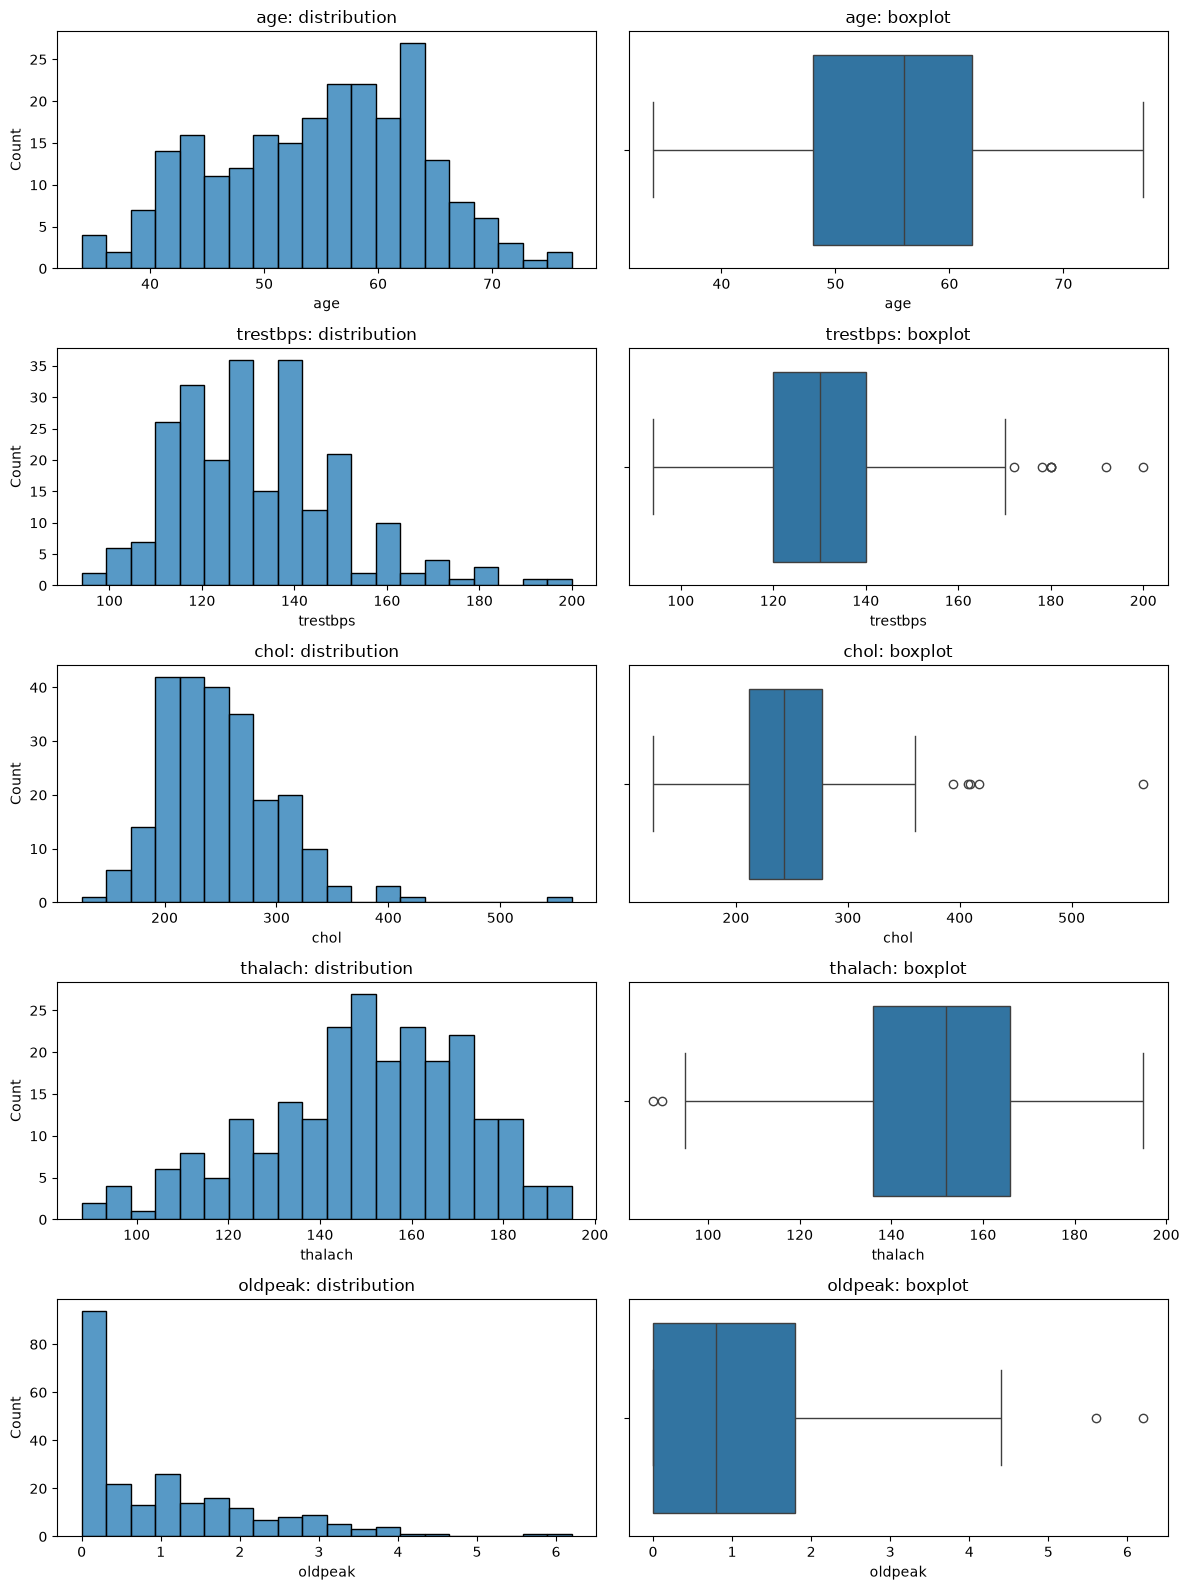

In [12]:
# Plot the five measurements.
# We will examine ca separately because it is a discrete count.
measurement_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

fig, axes = plt.subplots(
    nrows=len(measurement_features),
    ncols=2,
    figsize=(12, 16)
)

for row, column in enumerate(measurement_features):

    # Left: distribution of values.
    sns.histplot(
        data=X_train,
        x=column,
        bins=20,
        ax=axes[row, 0]
    )
    axes[row, 0].set_title(f"{column}: distribution")

    # Right: median, quartiles, and potential outliers.
    sns.boxplot(
        data=X_train,
        x=column,
        ax=axes[row, 1]
    )
    axes[row, 1].set_title(f"{column}: boxplot")

plt.tight_layout()
plt.show()

Data type: float64
Missing values: 0

Patients per ca value:
ca
0.0    136
1.0     55
2.0     32
3.0     14

Total patients counted: 237


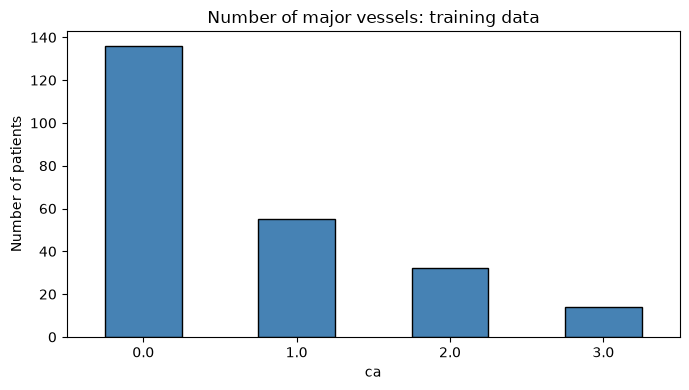

In [14]:
# Inspect the values currently stored in ca.
print("Data type:", X_train["ca"].dtype)
print("Missing values:", X_train["ca"].isna().sum())

ca_counts = X_train["ca"].value_counts().sort_index()

print("\nPatients per ca value:")
print(ca_counts.to_string())
print("\nTotal patients counted:", ca_counts.sum())

# Create a fresh figure and plot the calculated counts.
fig, ax = plt.subplots(figsize=(7, 4))

ca_counts.plot.bar(
    ax=ax,
    color="steelblue",
    edgecolor="black"
)

ax.set_title("Number of major vessels: training data")
ax.set_xlabel("ca")
ax.set_ylabel("Number of patients")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [15]:
# Inspect category codes without changing the data.
for column in binary_features + categorical_features:
    print(f"{column}: {sorted(X_train[column].unique())}")

sex: [np.int64(0), np.int64(1)]
fbs: [np.int64(0), np.int64(1)]
exang: [np.int64(0), np.int64(1)]
cp: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
restecg: [np.int64(0), np.int64(1), np.int64(2)]
slope: [np.int64(1), np.int64(2), np.int64(3)]
thal: [np.float64(3.0), np.float64(6.0), np.float64(7.0)]


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder
from sklearn.base import clone

# Category definitions come from the dataset's documented codes.
# Their order must match categorical_features:
# ["cp", "restecg", "slope", "thal"]
category_codes = [
    [1, 2, 3, 4],
    [0, 1, 2],
    [1, 2, 3],
    [3, 6, 7]
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            MinMaxScaler(feature_range=(0, 10)),
            numerical_features
        ),
        (
            "categorical",
            OrdinalEncoder(categories=category_codes),
            categorical_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Return transformed results as a labeled pandas DataFrame.
preprocessor.set_output(transform="pandas")

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per

In [17]:
# Fit a separate copy for inspection only.
preview_preprocessor = clone(preprocessor)

X_train_preview = preview_preprocessor.fit_transform(X_train)

print("Original training shape:", X_train.shape)
print("Transformed training shape:", X_train_preview.shape)

display(X_train_preview.head().round(3))

print("\nNumerical ranges after scaling:")
display(
    X_train_preview[numerical_features]
    .agg(["min", "max"])
    .round(3)
)

Original training shape: (237, 13)
Transformed training shape: (237, 13)


,age,trestbps,chol,thalach,oldpeak,ca,cp,restecg,slope,thal,sex,fbs,exang
55,4.651,2.830,3.196,1.963,3.548,3.333,3.0,2.0,1.0,2.0,1,0,1
160,2.791,0.660,1.621,6.355,0.000,0.000,1.0,0.0,0.0,2.0,1,1,0
178,2.093,3.396,4.315,6.916,3.065,3.333,2.0,0.0,0.0,0.0,1,0,0
86,3.023,4.151,2.991,6.355,0.000,0.000,2.0,2.0,0.0,0.0,1,0,0
79,5.581,5.283,3.288,2.150,1.290,0.000,3.0,2.0,0.0,2.0,1,0,1



Numerical ranges after scaling:


,age,trestbps,chol,thalach,oldpeak,ca
min,0.0,0.0,0.0,0.0,0.0,0.0
max,10.0,10.0,10.0,10.0,10.0,10.0


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

# Define the four classifiers.
models = {
    "Logistic Regression": LogisticRegression(
        C=0.1,
        l1_ratio=0,
        solver="lbfgs",
        max_iter=5000,
        random_state=1
    ),

    "Support Vector Machine": SVC(
        C=3,
        kernel="rbf",
        gamma=0.65,
        random_state=0
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=7,
        metric="euclidean"
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=5
    )
}

# Give each model its own preprocessing procedure.
pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model))
        ]
    )

print("Pipelines created:")

for name in pipelines:
    print("-", name)

Pipelines created:
- Logistic Regression
- Support Vector Machine
- K-Nearest Neighbors
- Decision Tree


In [19]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define the same six folds for all four models.
cv = StratifiedKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

# Specify the evaluation metrics.
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Store both the individual fold results and their summaries.
cv_results = {}
summary_rows = []

for name, pipeline in pipelines.items():
    print(f"Evaluating: {name}")

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    cv_results[name] = scores

    summary_rows.append({
        "Model": name,
        "Train accuracy": scores["train_accuracy"].mean(),
        "CV accuracy": scores["test_accuracy"].mean(),
        "CV precision": scores["test_precision"].mean(),
        "CV recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC SD": scores["test_roc_auc"].std(ddof=1)
    })

cv_summary = (
    pd.DataFrame(summary_rows)
    .set_index("Model")
    .sort_values("CV ROC-AUC", ascending=False)
)

display(cv_summary.round(3))

Evaluating: Logistic Regression
Evaluating: Support Vector Machine
Evaluating: K-Nearest Neighbors
Evaluating: Decision Tree


,Train accuracy,CV accuracy,CV precision,CV recall,CV F1,CV ROC-AUC,ROC-AUC SD
Model,,,,,,,
Logistic Regression,0.863,0.819,0.833,0.760,0.784,0.878,0.090
K-Nearest Neighbors,0.829,0.777,0.783,0.705,0.731,0.860,0.093
Support Vector Machine,1.000,0.582,0.661,0.128,0.212,0.741,0.135
Decision Tree,1.000,0.705,0.671,0.705,0.686,0.704,0.081


In [20]:
# Candidate settings for each model.
# "model__" refers to the model step inside each pipeline.

param_grids = {
    "Logistic Regression": {
        "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
    },

    "Support Vector Machine": [
        {
            "model__kernel": ["rbf"],
            "model__C": [0.01, 0.1, 1, 3, 10],
            "model__gamma": ["scale", 0.001, 0.01, 0.1, 0.65]
        },
        {
            "model__kernel": ["linear"],
            "model__C": [0.01, 0.1, 1, 3, 10]
        }
    ],

    "K-Nearest Neighbors": {
        "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "model__weights": ["uniform", "distance"]
    },

    "Decision Tree": {
        "model__max_depth": [2, 3, 4, 5, None],
        "model__min_samples_leaf": [1, 3, 5, 10],
        "model__criterion": ["gini", "entropy"]
    }
}

# Count the candidate combinations.
from sklearn.model_selection import ParameterGrid

for name, grid in param_grids.items():
    combinations = len(ParameterGrid(grid))
    print(
        f"{name}: {combinations} combinations, "
        f"{combinations * cv.get_n_splits()} CV fits"
    )

Logistic Regression: 6 combinations, 36 CV fits
Support Vector Machine: 30 combinations, 180 CV fits
K-Nearest Neighbors: 14 combinations, 84 CV fits
Decision Tree: 40 combinations, 240 CV fits


In [21]:
from sklearn.model_selection import GridSearchCV

# Store complete searches and the selected fitted pipelines.
searches = {}
best_models = {}
tuning_rows = []

for name, pipeline in pipelines.items():
    print(f"\nTuning: {name}", flush=True)

    search = GridSearchCV(
        estimator=clone(pipeline),
        param_grid=param_grids[name],
        scoring=scoring,
        refit="roc_auc",
        cv=cv,
        n_jobs=1,
        return_train_score=True,
        error_score="raise",
        verbose=1
    )

    # Pass raw training predictors.
    # Each pipeline handles its own encoding and scaling.
    search.fit(X_train, y_train)

    searches[name] = search
    best_models[name] = search.best_estimator_

    # Locate the selected combination in the search results.
    best_index = search.best_index_
    results = search.cv_results_

    tuning_rows.append({
        "Model": name,
        "Train accuracy": results["mean_train_accuracy"][best_index],
        "CV accuracy": results["mean_test_accuracy"][best_index],
        "CV precision": results["mean_test_precision"][best_index],
        "CV recall": results["mean_test_recall"][best_index],
        "CV F1": results["mean_test_f1"][best_index],
        "CV ROC-AUC": results["mean_test_roc_auc"][best_index]
    })

    print("Best parameters:", search.best_params_)
    print(f"Best mean CV ROC-AUC: {search.best_score_:.3f}")

tuned_summary = (
    pd.DataFrame(tuning_rows)
    .set_index("Model")
    .sort_values("CV ROC-AUC", ascending=False)
)

display(tuned_summary.round(3))


Tuning: Logistic Regression
Fitting 6 folds for each of 6 candidates, totalling 36 fits
Best parameters: {'model__C': 10}
Best mean CV ROC-AUC: 0.878

Tuning: Support Vector Machine
Fitting 6 folds for each of 30 candidates, totalling 180 fits


C:\Users\Carlos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Carlos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Carlos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py

Best parameters: {'model__C': 1, 'model__kernel': 'linear'}
Best mean CV ROC-AUC: 0.884

Tuning: K-Nearest Neighbors
Fitting 6 folds for each of 14 candidates, totalling 84 fits
Best parameters: {'model__n_neighbors': 9, 'model__weights': 'distance'}
Best mean CV ROC-AUC: 0.862

Tuning: Decision Tree
Fitting 6 folds for each of 40 candidates, totalling 240 fits
Best parameters: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 10}
Best mean CV ROC-AUC: 0.869


,Train accuracy,CV accuracy,CV precision,CV recall,CV F1,CV ROC-AUC
Model,,,,,,
Support Vector Machine,0.856,0.819,0.845,0.760,0.788,0.884
Logistic Regression,0.856,0.815,0.822,0.769,0.787,0.878
Decision Tree,0.850,0.802,0.806,0.769,0.778,0.869
K-Nearest Neighbors,1.000,0.785,0.800,0.705,0.742,0.862


In [22]:
comparison = pd.DataFrame({
    "Before tuning CV AUC": cv_summary["CV ROC-AUC"],
    "After tuning CV AUC": tuned_summary["CV ROC-AUC"]
})

comparison["AUC change"] = (
    comparison["After tuning CV AUC"]
    - comparison["Before tuning CV AUC"]
)

display(
    comparison
    .sort_values("After tuning CV AUC", ascending=False)
    .round(3)
)

,Before tuning CV AUC,After tuning CV AUC,AUC change
Model,,,
Support Vector Machine,0.741,0.884,0.143
Logistic Regression,0.878,0.878,0.001
Decision Tree,0.704,0.869,0.164
K-Nearest Neighbors,0.860,0.862,0.002


In [23]:
for name, search in searches.items():
    print(f"\n{name}")
    print(f"Selected mean CV ROC-AUC: {search.best_score_:.4f}")

    for parameter, value in search.best_params_.items():
        # Remove the pipeline prefix to make the output easier to read.
        short_name = parameter.replace("model__", "")
        print(f"  {short_name}: {value}")


Logistic Regression
Selected mean CV ROC-AUC: 0.8785
  C: 10

Support Vector Machine
Selected mean CV ROC-AUC: 0.8842
  C: 1
  kernel: linear

K-Nearest Neighbors
Selected mean CV ROC-AUC: 0.8619
  n_neighbors: 9
  weights: distance

Decision Tree
Selected mean CV ROC-AUC: 0.8688
  criterion: gini
  max_depth: 3
  min_samples_leaf: 10


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Record the selection made using cross-validation only.
selected_model_name = max(
    searches,
    key=lambda name: searches[name].best_score_
)

print("Model selected by CV:", selected_model_name)

# Store predictions for later confusion matrices and ROC plots.
test_predictions = {}
test_scores = {}
test_rows = []

for name, model in best_models.items():

    # Predict class labels: 0 or 1.
    y_pred = model.predict(X_test)

    # Obtain continuous scores for ROC-AUC.
    if hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)
    else:
        # Find the probability column corresponding to disease = 1.
        positive_index = list(model.classes_).index(1)
        y_score = model.predict_proba(X_test)[:, positive_index]

    test_predictions[name] = y_pred
    test_scores[name] = y_score

    # Rows = actual classes; columns = predicted classes.
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

test_summary = pd.DataFrame(test_rows).set_index("Model")

display(test_summary.round(3))

Model selected by CV: Support Vector Machine


,Accuracy,Precision,Recall,F1,ROC-AUC,TN,FP,FN,TP
Model,,,,,,,,,
Logistic Regression,0.833,0.846,0.786,0.815,0.950,28,4,6,22
Support Vector Machine,0.867,0.885,0.821,0.852,0.953,29,3,5,23
K-Nearest Neighbors,0.833,0.875,0.750,0.808,0.956,29,3,7,21
Decision Tree,0.800,0.833,0.714,0.769,0.889,28,4,8,20


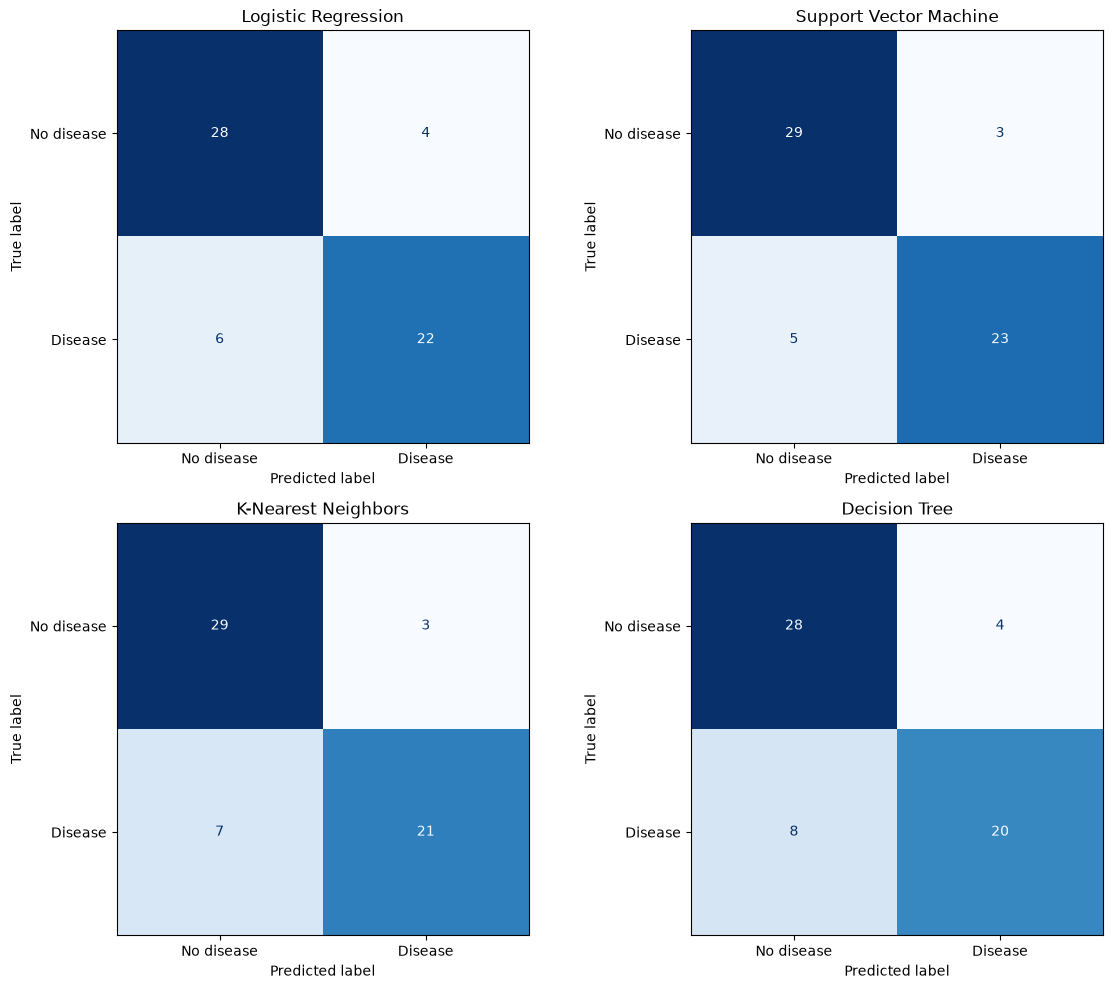

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(
    axes.ravel(),
    test_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["No disease", "Disease"],
        cmap="Blues",
        colorbar=False,
        values_format="d",
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

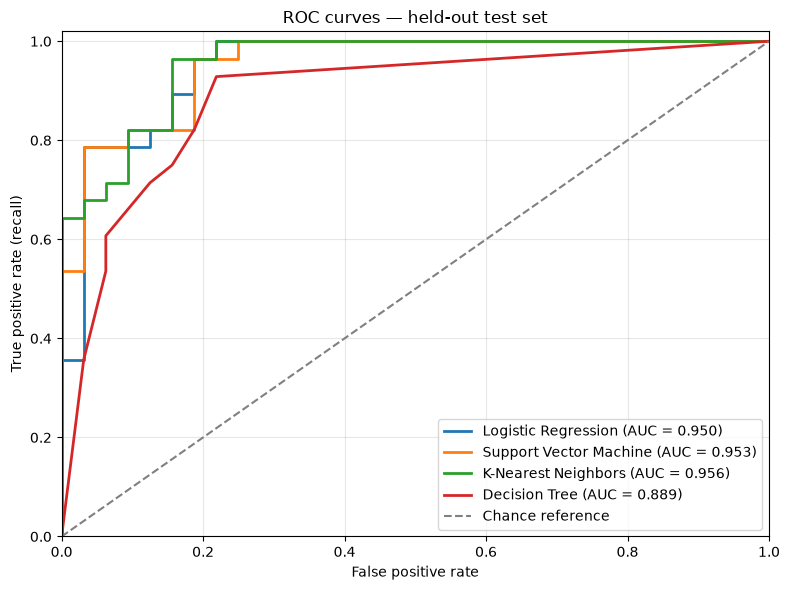

In [26]:
from sklearn.metrics import roc_curve, roc_auc_score

fig, ax = plt.subplots(figsize=(8, 6))

for name, scores in test_scores.items():

    # Calculate rates across classification thresholds.
    fpr, tpr, thresholds = roc_curve(
        y_test,
        scores,
        pos_label=1
    )

    auc_value = roc_auc_score(y_test, scores)

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

# Reference line for chance-level ranking.
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference"
)

ax.set(
    xlabel="False positive rate",
    ylabel="True positive rate (recall)",
    title="ROC curves — held-out test set",
    xlim=(0, 1),
    ylim=(0, 1.02)
)

ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()